In [83]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import chi2_contingency
import prince  # Bibliothèque pour ACM / MCA, faire pip install --upgrade prince scikit-learn pandas numpy si nécessaire

# pip install fastcluster
import fastcluster
from scipy.cluster.hierarchy import dendrogram, fcluster
from sklearn.cluster import KMeans
from sklearn.metrics import pairwise_distances_argmin, silhouette_score

from itertools import combinations
from IPython.display import display

In [84]:
# Charger le jeu de données depuis le dossier data
chemin_fichier = "../data/td_clustering_karafun.csv"
data = pd.read_csv(chemin_fichier)

# Structure y dimension
print(data.info())
print("Lignes et colonnes :", data.shape)

# Valeurs nulles
print(data.isnull().sum())

# Valeurs dupliquées
print("Valeurs dupliquées :", data.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 341092 entries, 0 to 341091
Data columns (total 16 columns):
 #   Column                      Non-Null Count   Dtype
---  ------                      --------------   -----
 0   id_anonyme                  341092 non-null  str  
 1   anciennete_client_tr        341092 non-null  str  
 2   anciennete_abonnement_tr    341092 non-null  str  
 3   statut_abonnement           341092 non-null  str  
 4   type_client                 341092 non-null  str  
 5   type_very_first_abo         341092 non-null  str  
 6   type_first_abo_last_streak  341092 non-null  str  
 7   ratio_fidelite_tr           341092 non-null  str  
 8   methode_paiement            341092 non-null  str  
 9   nb_abo_periode              341092 non-null  int64
 10  valeur_12M_tr               341092 non-null  str  
 11  avg_sessions_actifs_tr      341092 non-null  str  
 12  avg_songs_sessions_tr       341092 non-null  str  
 13  utilise_remote              341092 non-null  str  
 14 

In [85]:
### RECODAGE ###

# 1. Dictionnaire de remappage des modalités
dictionnaire_anciennete = {
    # Moins de 6 mois (~19.9%)
    '00_moins_1_mois': '01_Moins_de_6_mois',
    '01_1_mois': '01_Moins_de_6_mois',
    '02_2_mois': '01_Moins_de_6_mois',
    '03_3_mois': '01_Moins_de_6_mois',
    '04_4_mois': '01_Moins_de_6_mois',
    '05_5_mois': '01_Moins_de_6_mois',
    
    # 6 à 12 mois (~28.9%)
    '06_6_mois': '02_6_a_12_mois',
    '07_7a9_mois': '02_6_a_12_mois',
    '08_10a12_mois': '02_6_a_12_mois',
    
    # 1 à 2 ans (~18.5%)
    '09_13a15_mois': '03_1_a_2_ans',
    '10_16a18_mois': '03_1_a_2_ans',
    '11_19a21_mois': '03_1_a_2_ans',
    '12_22a24_mois': '03_1_a_2_ans',
    
    # 2 à 4 ans (~18.6%)
    '13_25a30_mois': '04_2_a_4_ans',
    '14_31a36_mois': '04_2_a_4_ans',
    '15_37a48_mois': '04_2_a_4_ans',
    
    # Plus de 4 ans (~14.1%)
    '16_49a60_mois': '05_Plus_de_4_ans',
    '17_61a84_mois': '05_Plus_de_4_ans',
    '18_85a120_mois': '05_Plus_de_4_ans',
    '19_121_mois_et_plus': '05_Plus_de_4_ans'
}

# 2. Application du regroupement dans le DataFrame
data['anciennete_client_rec'] = data['anciennete_client_tr'].map(dictionnaire_anciennete)

# 3. Vérification des nouvelles fréquences et pourcentages
distribution_rec = pd.DataFrame({
    'Fréquence': data['anciennete_client_rec'].value_counts(),
    'Pourcentage (%)': (data['anciennete_client_rec'].value_counts(normalize=True) * 100).round(2)
})

print(distribution_rec)

                       Fréquence  Pourcentage (%)
anciennete_client_rec                            
02_6_a_12_mois             98460            28.87
01_Moins_de_6_mois         67839            19.89
04_2_a_4_ans               63540            18.63
03_1_a_2_ans               62931            18.45
05_Plus_de_4_ans           48322            14.17


In [86]:
# 1. Dictionnaire de remappage des modalités
dict_anciennete_abo = {
    # Moins de 3 mois (~20.47%)
    '00_moins_1_mois': '01_Moins_de_3_mois',
    '01_1_mois': '01_Moins_de_3_mois',
    '02_2_mois': '01_Moins_de_3_mois',
    
    # 3 à 5 mois (~15.45%)
    '03_3_mois': '02_3_a_5_mois',
    '04_4_mois': '02_3_a_5_mois',
    '05_5_mois': '02_3_a_5_mois',
    
    # 6 à 12 mois (~38.67%)
    '06_6_mois': '03_6_a_12_mois',
    '07_7a9_mois': '03_6_a_12_mois',
    '08_10a12_mois': '03_6_a_12_mois',
    
    # 1 à 2 ans (~13.31%)
    '09_13a15_mois': '04_1_a_2_ans',
    '10_16a18_mois': '04_1_a_2_ans',
    '11_19a21_mois': '04_1_a_2_ans',
    '12_22a24_mois': '04_1_a_2_ans',
    
    # Plus de 2 ans (~12.11%)
    '13_25a30_mois': '05_Plus_de_2_ans',
    '14_31a36_mois': '05_Plus_de_2_ans',
    '15_37a48_mois': '05_Plus_de_2_ans',
    '16_49a60_mois': '05_Plus_de_2_ans',
    '17_61a84_mois': '05_Plus_de_2_ans',
    '18_85a120_mois': '05_Plus_de_2_ans',
    '19_121_mois_et_plus': '05_Plus_de_2_ans'
}

# 2. Application du regroupement
data['anciennete_abonnement_rec'] = data['anciennete_abonnement_tr'].map(dict_anciennete_abo)

# 3. Vérification des nouvelles fréquences et pourcentages
distribution_abo_rec = pd.DataFrame({
    'Fréquence': data['anciennete_abonnement_rec'].value_counts(),
    'Pourcentage (%)': (data['anciennete_abonnement_rec'].value_counts(normalize=True) * 100).round(2)
})

print(distribution_abo_rec)

                           Fréquence  Pourcentage (%)
anciennete_abonnement_rec                            
03_6_a_12_mois                131874            38.66
01_Moins_de_3_mois             69795            20.46
02_3_a_5_mois                  52697            15.45
04_1_a_2_ans                   45378            13.30
05_Plus_de_2_ans               41348            12.12


In [87]:
# 1. Dictionnaire de remappage selon les spécifications métier
dict_methode_paiement = {
    # Regroupement Web / Paiements directs (Règle métier : Stripe et Paypal sont équivalents)
    'Stripe': 'web_et_direct',
    'Paypal': 'web_et_direct',
    
    # Regroupement Mobile / Application Store (Apple et Android regroupés sous 'telephone')
    'Apple': 'telephone',
    'Android': 'telephone',
    
    # Conservation des méthodes minoritaires séparées selon la demande
    'Amazon': 'Amazon',
    'Credit': 'Credit',
    'Others': 'Others' # Ligne unique à supprimer ultérieurement dans le nettoyage
}

# 2. Application de la transformation dans 'data'
data['methode_paiement_rec'] = data['methode_paiement'].map(dict_methode_paiement)

# 3. Vérification de la distribution
distribution_paiement = pd.DataFrame({
    'Fréquence': data['methode_paiement_rec'].value_counts(),
    'Pourcentage (%)': (data['methode_paiement_rec'].value_counts(normalize=True) * 100).round(2)
})

print("=== Distribution de methode_paiement_rec ===")
print(distribution_paiement)

=== Distribution de methode_paiement_rec ===
                      Fréquence  Pourcentage (%)
methode_paiement_rec                            
web_et_direct            172829            50.67
telephone                164814            48.32
Amazon                     2846             0.83
Credit                      602             0.18
Others                        1             0.00


In [88]:
# 1. Dictionnaire de remappage pour la valeur financière sur 12 mois
dict_valeur_12M = {
    # Moins de 15 (~37.71%)
    '00_moins_10': '01_Moins_de_15',
    '01_10a15': '01_Moins_de_15',
    
    # 15 à 30 (~14.41%)
    '02_15a20': '02_15_a_30',
    '03_20a25': '02_15_a_30',
    '04_25a30': '02_15_a_30',
    
    # 30 à 50 (~13.38%)
    '05_30a40': '03_30_a_50',
    '06_40a50': '03_30_a_50',
    
    # 50 à 90 (~25.25%)
    '07_50a60': '04_50_a_90',
    '08_60a70': '04_50_a_90',
    '09_70a90': '04_50_a_90',
    
    # Plus de 90 (~9.26%)
    '10_90a110': '05_Plus_de_90',
    '11_110_et_plus': '05_Plus_de_90'
}

# 2. Application de la transformation dans 'data'
data['valeur_12M_rec'] = data['valeur_12M_tr'].map(dict_valeur_12M)

# 3. Vérification de la nouvelle distribution
distribution_valeur = pd.DataFrame({
    'Fréquence': data['valeur_12M_rec'].value_counts(),
    'Pourcentage (%)': (data['valeur_12M_rec'].value_counts(normalize=True) * 100).round(2)
})

print("=== Distribution de valeur_12M_rec ===")
print(distribution_valeur)

=== Distribution de valeur_12M_rec ===
                Fréquence  Pourcentage (%)
valeur_12M_rec                            
01_Moins_de_15     128630            37.71
04_50_a_90          86115            25.25
02_15_a_30          49154            14.41
03_30_a_50          45618            13.37
05_Plus_de_90       31575             9.26


In [89]:
# 1. Dictionnaire de remappage pour le nombre moyen de sessions
dict_avg_sessions = {
    # Inactifs (~11.94%)
    '00_pas_de_session': '00_Inactif',
    
    # Usage faible (~42.28%)
    '01_moins_1': '01_Faible_1_a_2',
    '02_1a2': '01_Faible_1_a_2',
    
    # Usage moyen (~22.28%)
    '03_2a3': '02_Moyen_2_a_4',
    '04_3a4': '02_Moyen_2_a_4',
    
    # Usage élevé (~13.81%)
    '05_4a5': '03_Eleve_4_a_8',
    '06_5a6': '03_Eleve_4_a_8',
    '07_6a8': '03_Eleve_4_a_8',
    
    # Très forts utilisateurs / Power users (~9.69%)
    '08_8a10': '04_Tres_eleve_8_et_plus',
    '09_10a15': '04_Tres_eleve_8_et_plus',
    '10_15a20': '04_Tres_eleve_8_et_plus',
    '11_20a30': '04_Tres_eleve_8_et_plus',
    '12_30a50': '04_Tres_eleve_8_et_plus',
    '13_50_et_plus': '04_Tres_eleve_8_et_plus'
}

# 2. Application du regroupement dans 'data'
data['avg_sessions_actifs_rec'] = data['avg_sessions_actifs_tr'].map(dict_avg_sessions)

# 3. Vérification de la nouvelle distribution
distribution_sessions = pd.DataFrame({
    'Fréquence': data['avg_sessions_actifs_rec'].value_counts(),
    'Pourcentage (%)': (data['avg_sessions_actifs_rec'].value_counts(normalize=True) * 100).round(2)
})

print("=== Distribution de avg_sessions_actifs_rec ===")
print(distribution_sessions)

=== Distribution de avg_sessions_actifs_rec ===
                         Fréquence  Pourcentage (%)
avg_sessions_actifs_rec                            
01_Faible_1_a_2             144215            42.28
02_Moyen_2_a_4               75968            22.27
03_Eleve_4_a_8               47134            13.82
00_Inactif                   40716            11.94
04_Tres_eleve_8_et_plus      33059             9.69


In [90]:
# 1. Dictionnaire de remappage pour le nombre moyen de chansons par session
dict_avg_songs = {
    # Inactifs (~11.94%)
    '00_pas_de_session': '00_Inactif',
    
    # Écoute faible : 1 à 5 titres (~28.44%)
    '01_1a2': '01_Faible_1_a_5',
    '02_2a3': '01_Faible_1_a_5',
    '03_3a4': '01_Faible_1_a_5',
    '04_4a5': '01_Faible_1_a_5',
    
    # Écoute moyenne : 5 à 10 titres (~23.72%)
    '05_5a6': '02_Moyen_5_a_10',
    '06_6a8': '02_Moyen_5_a_10',
    '07_8a10': '02_Moyen_5_a_10',
    
    # Écoute élevée : 10 à 20 titres (~22.51%)
    '08_10a15': '03_Eleve_10_a_20',
    '09_15a20': '03_Eleve_10_a_20',
    
    # Écoute très élevée : 20 titres et plus (~13.38%)
    '10_20a30': '04_Tres_eleve_20_et_plus',
    '11_30a50': '04_Tres_eleve_20_et_plus',
    '12_50_et_plus': '04_Tres_eleve_20_et_plus'
}

# 2. Application du regroupement dans 'data'
data['avg_songs_sessions_rec'] = data['avg_songs_sessions_tr'].map(dict_avg_songs)

# 3. Vérification de la nouvelle distribution
distribution_songs = pd.DataFrame({
    'Fréquence': data['avg_songs_sessions_rec'].value_counts(),
    'Pourcentage (%)': (data['avg_songs_sessions_rec'].value_counts(normalize=True) * 100).round(2)
})

print("=== Distribution de avg_songs_sessions_rec ===")
print(distribution_songs)

=== Distribution de avg_songs_sessions_rec ===
                          Fréquence  Pourcentage (%)
avg_songs_sessions_rec                              
01_Faible_1_a_5               97035            28.45
02_Moyen_5_a_10               80920            23.72
03_Eleve_10_a_20              76782            22.51
04_Tres_eleve_20_et_plus      45639            13.38
00_Inactif                    40716            11.94


In [91]:
# 1. Dictionnaire de remappage géographique
dict_zone_geo = {
    # Marché américain principal
    'US': '01_US',
    
    # Bloc Europe (Europe, France et Royaume-Uni : ~45.73%)
    'Europe': '02_Europe',
    'FR': '02_Europe',
    'UK': '02_Europe',
    
    # Canada (~7.04%)
    'CA': '03_CA',
    
    # Regroupement des zones < 3% (~5.94%)
    'Oceanie': '04_Reste_du_Monde',
    'Asie': '04_Reste_du_Monde',
    'Amerique_Nord_Autre': '04_Reste_du_Monde',
    'Amerique_Sud': '04_Reste_du_Monde',
    'Afrique': '04_Reste_du_Monde',
    'Autre/Inconnu': '04_Reste_du_Monde'
}

# 2. Application de la transformation
data['zone_geo_rec'] = data['zone_geo'].map(dict_zone_geo)

# 3. Vérification de la nouvelle distribution
distribution_geo = pd.DataFrame({
    'Fréquence': data['zone_geo_rec'].value_counts(),
    'Pourcentage (%)': (data['zone_geo_rec'].value_counts(normalize=True) * 100).round(2)
})

print("=== Distribution de zone_geo_rec ===")
print(distribution_geo)

=== Distribution de zone_geo_rec ===
                   Fréquence  Pourcentage (%)
zone_geo_rec                                 
02_Europe             155980            45.73
01_US                 140842            41.29
03_CA                  23999             7.04
04_Reste_du_Monde      20271             5.94


In [92]:
# 1. Liste des variables d'origine à supprimer :
# - Variables ayant été recodées en version '_rec'
# - Variables sans pouvoir explicatif (modalité quasi-unique / variance nulle)
vars_a_supprimer = [
    # Variables recodées
    'id_anonyme',
    'anciennete_client_tr',
    'anciennete_abonnement_tr',
    'methode_paiement',
    'valeur_12M_tr',
    'avg_sessions_actifs_tr',
    'avg_songs_sessions_tr',
    'zone_geo',
    
    # Variables supprimées car quasi-constantes (une seule modalité dominante, aucun pouvoir explicatif)
    'type_very_first_abo',
    'type_first_abo_last_streak'
]

# 2. Suppression de la ligne unique 'Others' avant la création de data_clean
data = data[data['methode_paiement'] != 'Others'].copy()

# 3. Création du DataFrame nettoyé
data_clean = data.drop(columns=vars_a_supprimer)

# 4. Identification automatique des variables qualitatives restantes
var_quali = [
    col for col in data_clean.select_dtypes(include=['object', 'category']).columns 
    if col != 'id_anonyme'
]


C:\Users\zejes\AppData\Local\Temp\ipykernel_12340\1643740415.py:28: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  col for col in data_clean.select_dtypes(include=['object', 'category']).columns


In [93]:
### ACM ###

# ===== PARÁMETROS GLOBALES =====
GRAINE = 42
NUMERO_ITERATION = 1
N_COMPOSANTES = 15           # axes calculés (doit dépasser le nombre d'axes avec λ > 1/p pour Benzécri)
N_AXES_TABLEAU = 5           # axes affichés dans le tableau coordonnées / contributions
N_AXES_PROXIMITE = 5         # axes utilisés pour la distance entre modalités (<= N_AXES_TABLEAU)
FACTEUR_SEUIL = 1.0          # 1.0 = seuil moyen 100/K

# Seuil de proximité calculé automatiquement
# à partir du 10e percentile des distances
QUANTILE_PROXIMITE = 0.10
SEUIL_PROXIMITE = None  # Calculé après le calcul des distances
# Variables toujours exclues (identifiant, variable illustrative)
VARIABLES_EXCLUES = ['id_anonyme', 'statut_abonnement']

# Variables retirées à cette itération (Modifiales ici ou dans le bloc d'itération si tu fais une suite)
VARIABLES_A_RETIRER = []

In [94]:
# ===== FONCTIONS DE CALCUL ET D'INERTIE =====
def variable_de(modalite):
    """Retourne le nom de la variable à partir du nom de la colonne (variable__modalite)."""
    return modalite.split('__')[0]

def inertie_brute(valeurs_propres, inertie_totale):
    """Inertie brute (en %) de chaque axe : valeur propre / inertie totale."""
    return np.array(valeurs_propres) / inertie_totale * 100

def inertie_benzecri(valeurs_propres, nb_var):
    """Inertie corrigée de Benzécri (en %) pour chaque axe."""
    seuil = 1 / nb_var
    corrigees = np.array([
        ((nb_var / (nb_var - 1)) ** 2) * ((lam - seuil) ** 2) if lam > seuil else 0
        for lam in valeurs_propres
    ])
    return corrigees / corrigees.sum() * 100

# ===== FONCTIONS DE MISE EN ÉVIDENCE (STYLES LISIBLES) =====
def surligner_modalites_par_axe(df, col_coord, col_contrib, seuil_contribution, variables_a_revoir):
    styles = pd.DataFrame('', index=df.index, columns=df.columns)
    # Vert pastel doux avec texte foncé pour le contraste
    style_vert = 'background-color: #e2f0d9; color: #1b3a12; font-weight: bold;'
    styles.loc[df[col_contrib] > seuil_contribution, col_contrib] = style_vert
    styles.loc[df[col_contrib] > seuil_contribution, col_coord] = style_vert
    styles.loc[df['Variable'].isin(variables_a_revoir), ['Variable', 'Modalité']] = 'background-color: #fce4d6; color: #5c1d06;'
    return styles

def surligner_resume(df, seuil_contribution):
    styles = pd.DataFrame('', index=df.index, columns=df.columns)
    styles.loc[df['Statut'] != 'OK', :] = 'background-color: #fce4d6; color: #5c1d06;'
    for c in [col for col in df.columns if col.startswith('Max Axe')]:
        styles.loc[df[c] > seuil_contribution, c] = 'background-color: #e2f0d9; color: #1b3a12; font-weight: bold;'
    return styles

def surligner_proximite(df):
    styles = pd.DataFrame('', index=df.index, columns=df.columns)
    styles.loc[df['Proches ?'] == 'OUI', :] = 'background-color: #fff2cc; color: #594500;'
    return styles

In [95]:
# ITERATION 1

# ===== 1. ÉCHANTILLON DE 20 % (mêmes individus à chaque itération) =====
variables_acm = [
    col for col in data_clean.select_dtypes(include=['object', 'category']).columns
    if col not in VARIABLES_EXCLUES
]
indices_echantillon = data_clean.sample(frac=0.20, random_state=GRAINE).index
echantillon_acm = data_clean.loc[indices_echantillon, variables_acm]
print(f"Itération {NUMERO_ITERATION} : {len(echantillon_acm)} individus, {len(variables_acm)} variables")

# ===== 2. TABLEAU DISJONCTIF COMPLET =====
tableau_disjonctif = pd.get_dummies(echantillon_acm, prefix_sep='__').astype(float)
nb_modalites = tableau_disjonctif.shape[1]
nb_variables = len(variables_acm)
print(f"Nombre de modalités actives (K) : {nb_modalites}")


C:\Users\zejes\AppData\Local\Temp\ipykernel_12340\1135294764.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  col for col in data_clean.select_dtypes(include=['object', 'category']).columns


Itération 1 : 68218 individus, 11 variables
Nombre de modalités actives (K) : 47


In [96]:

# ===== 3. AJUSTEMENT DE L'ACM (AFC sur le tableau disjonctif) =====
modele = prince.CA(
    n_components=N_COMPOSANTES,
    n_iter=10,
    copy=True,
    check_input=True,
    engine='sklearn',
    random_state=GRAINE
)
modele = modele.fit(tableau_disjonctif)

# ===== 4. TABLEAU D'INERTIE =====
valeurs_propres = np.array(modele.eigenvalues_)
inertie_totale = (nb_modalites - nb_variables) / nb_variables
brute = inertie_brute(valeurs_propres, inertie_totale)
benzecri = inertie_benzecri(valeurs_propres, nb_variables)
nb_axes_utiles = int((valeurs_propres > 1 / nb_variables).sum())

df_inertie = pd.DataFrame({
    'Axe': [f'Axe {i + 1}' for i in range(len(valeurs_propres))],
    'Valeur Propre': valeurs_propres,
    'λ > 1/p': np.where(valeurs_propres > 1 / nb_variables, 'oui', 'non'),
    'Inertie Brute (%)': brute,
    'Inertie Brute Cumulée (%)': np.cumsum(brute),
    'Inertie Benzécri (%)': benzecri,
    'Inertie Benzécri Cumulée (%)': np.cumsum(benzecri)
})

print(f"\n=== Inertie expliquée par les axes factoriels (p = {nb_variables} variables, 1/p = {1 / nb_variables:.3f}) ===")
print(df_inertie.round(2).to_string(index=False))



=== Inertie expliquée par les axes factoriels (p = 11 variables, 1/p = 0.091) ===
   Axe  Valeur Propre λ > 1/p  Inertie Brute (%)  Inertie Brute Cumulée (%)  Inertie Benzécri (%)  Inertie Benzécri Cumulée (%)
 Axe 1           0.30     oui               9.29                       9.29                 51.67                         51.67
 Axe 2           0.23     oui               7.16                      16.45                 23.42                         75.09
 Axe 3           0.19     oui               5.85                      22.30                 11.54                         86.63
 Axe 4           0.16     oui               4.88                      27.18                  5.37                         92.01
 Axe 5           0.15     oui               4.54                      31.71                  3.78                         95.79
 Axe 6           0.13     oui               3.95                      35.66                  1.68                         97.46
 Axe 7           0.12

In [ ]:
# ===== 5. COORDONNÉES + CONTRIBUTIONS DES MODALITÉS =====
coordonnees = modele.column_coordinates(tableau_disjonctif).loc[tableau_disjonctif.columns].iloc[:, :N_AXES_TABLEAU]
contributions = modele.column_contributions_.loc[tableau_disjonctif.columns].iloc[:, :N_AXES_TABLEAU]
if np.isclose(contributions.sum().iloc[0], 1.0):
    contributions = contributions * 100

seuil_contribution = FACTEUR_SEUIL * 100 / nb_modalites
effectifs = tableau_disjonctif.sum(axis=0)

tableau_modalites = pd.DataFrame({
    'Variable': [variable_de(m) for m in tableau_disjonctif.columns],
    'Modalité': [m.split('__', 1)[1] for m in tableau_disjonctif.columns],
    'Effectif': effectifs.values.astype(int),
    'Fréquence (%)': effectifs.values / len(tableau_disjonctif) * 100
}, index=tableau_disjonctif.columns)

for i in range(N_AXES_TABLEAU):
    tableau_modalites[f'Coord Axe {i + 1}'] = coordonnees[i].values
    tableau_modalites[f'Contrib Axe {i + 1} (%)'] = contributions[i].values

colonnes_coord = [f'Coord Axe {i + 1}' for i in range(N_AXES_TABLEAU)]
colonnes_contrib = [f'Contrib Axe {i + 1} (%)' for i in range(N_AXES_TABLEAU)]

tableau_modalites['Contrib max (%)'] = tableau_modalites[colonnes_contrib].max(axis=1)


In [97]:

# ===== 5 BIS. PROXIMITÉS DE L'ACM INITIALE =====

from itertools import combinations

colonnes_proximite = [
    f"Coord Axe {i + 1}"
    for i in range(N_AXES_PROXIMITE)
]

distances = []

for variable, groupe in tableau_modalites.groupby("Variable", sort=False):
    for idx1, idx2 in combinations(groupe.index, 2):
        coord1 = tableau_modalites.loc[
            idx1, colonnes_proximite
        ].to_numpy(dtype=float)

        coord2 = tableau_modalites.loc[
            idx2, colonnes_proximite
        ].to_numpy(dtype=float)

        distances.append({
            "Variable": variable,
            "Modalité 1": tableau_modalites.loc[idx1, "Modalité"],
            "Modalité 2": tableau_modalites.loc[idx2, "Modalité"],
            "Distance": np.linalg.norm(coord1 - coord2)
        })

proximites = pd.DataFrame(distances)

if proximites.empty:
    raise ValueError(
        "Impossible de calculer le seuil : aucune distance disponible."
    )

# Calcul du seuil de référence sur l'ACM initiale uniquement
QUANTILE_PROXIMITE = 0.10

SEUIL_PROXIMITE_REFERENCE = proximites["Distance"].quantile(
    QUANTILE_PROXIMITE
)

print(f"Nombre de distances initiales : {len(proximites)}")
print(
    f"Seuil de proximité de référence "
    f"(quantile {QUANTILE_PROXIMITE:.0%}) : "
    f"{SEUIL_PROXIMITE_REFERENCE:.6f}"
)


Nombre de distances initiales : 85
Seuil de proximité de référence (quantile 10%) : 0.506196


In [98]:

# ===== 6. DIAGNOSTIC PAR VARIABLE =====
groupes = tableau_modalites.groupby('Variable', sort=False)
resume_variables = pd.DataFrame({
    'Nb modalités': groupes.size(),
    'Nb modalités > seuil': groupes['Contrib max (%)'].apply(lambda s: int((s > seuil_contribution).sum())),
    'Contrib max (%)': groupes['Contrib max (%)'].max()
})
for i in range(N_AXES_TABLEAU):
    resume_variables[f'Max Axe {i + 1} (%)'] = groupes[colonnes_contrib[i]].max()

resume_variables['Statut'] = np.where(resume_variables['Nb modalités > seuil'] == 0, 'À RETIRER ?', 'OK')
resume_variables = resume_variables.sort_values('Contrib max (%)')
variables_a_revoir = resume_variables.index[resume_variables['Statut'] != 'OK'].tolist()


In [99]:

# ===== 7. CONTRIBUTIONS ET DIAGNOSTIC PAR AXE =====

print(f"\nSeuil de contribution 100/K = {seuil_contribution:.2f} %")
format_base = {'Fréquence (%)': '{:.1f}'}

# Axes examinés pour le diagnostic
colonnes_contributions = [
    f'Contrib Axe {i + 1} (%)'
    for i in range(N_AXES_TABLEAU)
]

# Vérifier que toutes les colonnes nécessaires existent
colonnes_manquantes = [
    c for c in colonnes_contributions
    if c not in tableau_modalites.columns
]

if colonnes_manquantes:
    raise ValueError(
        f"Colonnes de contributions manquantes : {colonnes_manquantes}"
    )

# ===== DIAGNOSTIC PAR MODALITÉ =====

# Une modalité est significative si sa contribution atteint le seuil
# sur au moins un des axes examinés.
tableau_modalites["Statut modalité"] = np.where(
    tableau_modalites[colonnes_contributions]
    .ge(seuil_contribution)
    .any(axis=1),
    "OK",
    "NON SIGNIFICATIVE"
)

# ===== DIAGNOSTIC PAR VARIABLE =====

# Une variable est INACTIVE si aucune de ses modalités
# n'atteint le seuil sur aucun des axes examinés.
diagnostic_variables = (
    tableau_modalites
    .groupby("Variable", sort=True)
    .agg(
        Nombre_modalites=("Modalité", "nunique"),
        Au_moins_une_modalite_OK=(
            "Statut modalité",
            lambda s: s.eq("OK").any()
        )
    )
    .reset_index()
)

diagnostic_variables["Statut variable"] = np.where(
    diagnostic_variables["Au_moins_une_modalite_OK"],
    "OK",
    "INACTIVE"
)

# Liste des variables inactives
VARIABLES_A_INACTIVER = sorted(
    diagnostic_variables.loc[
        diagnostic_variables["Statut variable"] == "INACTIVE",
        "Variable"
    ].tolist()
)

# ===== AFFICHAGE DES CONTRIBUTIONS PAR AXE =====

print("\n=== Coordonnées et contributions des modalités par axe ===")

for i in range(N_AXES_TABLEAU):
    c_coord = f'Coord Axe {i + 1}'
    c_contrib = f'Contrib Axe {i + 1} (%)'

    cols_axe = [
        'Variable', 'Modalité', 'Effectif',
        'Fréquence (%)', c_coord, c_contrib,
        'Statut modalité'
    ]

    df_axe = tableau_modalites[cols_axe].copy()

    format_axe = format_base.copy()
    format_axe[c_coord] = '{:.3f}'
    format_axe[c_contrib] = '{:.2f}'

    print(f"\n--- Axe {i + 1} ---")

    display(
        df_axe.style
        .apply(
            lambda df: surligner_modalites_par_axe(
                df, c_coord, c_contrib,
                seuil_contribution, variables_a_revoir
            ),
            axis=None
        )
        .format(format_axe)
    )

# ===== TABLEAU RÉCAPITULATIF DES VARIABLES =====

print("\n=== Diagnostic final par variable ===")

display(
    diagnostic_variables.style
    .format({
        "Nombre_modalites": "{:.0f}"
    })
)

print("\n=== LISTE DES VARIABLES INACTIVES ===")
if VARIABLES_A_INACTIVER:
    for variable in VARIABLES_A_INACTIVER:
        print(f"- {variable}")
else:
    print("Aucune variable classée INACTIVE.")

print("\nNombre de variables OK :",
      int((diagnostic_variables["Statut variable"] == "OK").sum()))

print("Nombre de variables INACTIVES :",
      len(VARIABLES_A_INACTIVER))



Seuil de contribution 100/K = 2.13 %

=== Coordonnées et contributions des modalités par axe ===

--- Axe 1 ---


,Variable,Modalité,Effectif,Fréquence (%),Coord Axe 1,Contrib Axe 1 (%),Statut modalité
type_client__churn,type_client,churn,34314,50.3,-0.506,3.86,OK
type_client__nouveau,type_client,nouveau,10980,16.1,-0.522,1.31,OK
type_client__reactivated,type_client,reactivated,9932,14.6,0.085,0.03,OK
type_client__retained,type_client,retained,12992,19.0,1.714,16.73,OK
ratio_fidelite_tr__01_moins_30,ratio_fidelite_tr,01_moins_30,18647,27.3,-0.756,4.67,OK
ratio_fidelite_tr__02_30a50,ratio_fidelite_tr,02_30a50,7877,11.5,-0.356,0.44,OK
ratio_fidelite_tr__03_50a70,ratio_fidelite_tr,03_50a70,8087,11.9,-0.104,0.04,OK
ratio_fidelite_tr__04_70a90,ratio_fidelite_tr,04_70a90,6417,9.4,0.666,1.25,OK
ratio_fidelite_tr__05_90_et_plus,ratio_fidelite_tr,05_90_et_plus,24746,36.3,0.662,4.76,OK
ratio_fidelite_tr__99_vient_de_s_abonner,ratio_fidelite_tr,99_vient_de_s_abonner,2444,3.6,-1.193,1.53,OK



--- Axe 2 ---


,Variable,Modalité,Effectif,Fréquence (%),Coord Axe 2,Contrib Axe 2 (%),Statut modalité
type_client__churn,type_client,churn,34314,50.3,-0.635,7.87,OK
type_client__nouveau,type_client,nouveau,10980,16.1,1.468,13.46,OK
type_client__reactivated,type_client,reactivated,9932,14.6,0.402,0.91,OK
type_client__retained,type_client,retained,12992,19.0,0.129,0.12,OK
ratio_fidelite_tr__01_moins_30,ratio_fidelite_tr,01_moins_30,18647,27.3,-0.783,6.50,OK
ratio_fidelite_tr__02_30a50,ratio_fidelite_tr,02_30a50,7877,11.5,-0.413,0.76,OK
ratio_fidelite_tr__03_50a70,ratio_fidelite_tr,03_50a70,8087,11.9,-0.190,0.17,OK
ratio_fidelite_tr__04_70a90,ratio_fidelite_tr,04_70a90,6417,9.4,-0.254,0.24,OK
ratio_fidelite_tr__05_90_et_plus,ratio_fidelite_tr,05_90_et_plus,24746,36.3,0.619,5.40,OK
ratio_fidelite_tr__99_vient_de_s_abonner,ratio_fidelite_tr,99_vient_de_s_abonner,2444,3.6,2.332,7.56,OK



--- Axe 3 ---


...


--- Axe 5 ---


,Variable,Modalité,Effectif,Fréquence (%),Coord Axe 5,Contrib Axe 5 (%),Statut modalité
type_client__churn,type_client,churn,34314,50.3,0.077,0.18,OK
type_client__nouveau,type_client,nouveau,10980,16.1,-0.619,3.77,OK
type_client__reactivated,type_client,reactivated,9932,14.6,0.820,6.00,OK
type_client__retained,type_client,retained,12992,19.0,-0.309,1.11,OK
ratio_fidelite_tr__01_moins_30,ratio_fidelite_tr,01_moins_30,18647,27.3,-0.030,0.01,OK
ratio_fidelite_tr__02_30a50,ratio_fidelite_tr,02_30a50,7877,11.5,0.618,2.70,OK
ratio_fidelite_tr__03_50a70,ratio_fidelite_tr,03_50a70,8087,11.9,0.604,2.65,OK
ratio_fidelite_tr__04_70a90,ratio_fidelite_tr,04_70a90,6417,9.4,0.467,1.25,OK
ratio_fidelite_tr__05_90_et_plus,ratio_fidelite_tr,05_90_et_plus,24746,36.3,-0.516,5.90,OK
ratio_fidelite_tr__99_vient_de_s_abonner,ratio_fidelite_tr,99_vient_de_s_abonner,2444,3.6,0.232,0.12,OK



=== Diagnostic final par variable ===


,Variable,Nombre_modalites,Au_moins_une_modalite_OK,Statut variable
0,anciennete_abonnement_rec,5,True,OK
1,anciennete_client_rec,5,True,OK
2,avg_sessions_actifs_rec,5,True,OK
3,avg_songs_sessions_rec,5,True,OK
4,contactable,2,True,OK
5,methode_paiement_rec,4,True,OK
6,ratio_fidelite_tr,6,True,OK
7,type_client,4,True,OK
8,utilise_remote,2,True,OK
9,valeur_12M_rec,5,True,OK



=== LISTE DES VARIABLES INACTIVES ===
- zone_geo_rec

Nombre de variables OK : 10
Nombre de variables INACTIVES : 1


In [100]:

# ===== 8. MODALITÉS PROCHES =====

from itertools import combinations

lignes_proximite = []

# Exclure les variables explicitement exclues et celles
# identifiées comme inactives par le diagnostic de contributions
variables_exclues_proximite = (
    set(VARIABLES_EXCLUES)
    | set(VARIABLES_A_INACTIVER)
)

tableau_modalites_proximite = tableau_modalites[
    ~tableau_modalites["Variable"].isin(
        variables_exclues_proximite
    )
].copy()

# Coordonnées utilisées pour calculer les distances
colonnes_coord_proximite = [
    f"Coord Axe {i + 1}"
    for i in range(N_AXES_PROXIMITE)
]

# Vérification des paramètres
if N_AXES_PROXIMITE > N_AXES_TABLEAU:
    raise ValueError(
        "N_AXES_PROXIMITE ne peut pas dépasser N_AXES_TABLEAU."
    )

if SEUIL_PROXIMITE_REFERENCE is None:
    raise ValueError(
        "Le seuil de référence doit être calculé sur l'ACM initiale."
    )

# Calcul des distances entre modalités d'une même variable
for variable, groupe in tableau_modalites_proximite.groupby(
    "Variable", sort=True
):
    enregistrements = groupe.to_dict("records")

    for a, b in combinations(enregistrements, 2):
        vecteur_a = np.array(
            [a[c] for c in colonnes_coord_proximite],
            dtype=float
        )
        vecteur_b = np.array(
            [b[c] for c in colonnes_coord_proximite],
            dtype=float
        )

        lignes_proximite.append({
            "Variable": variable,
            "Modalité A": a["Modalité"],
            "Modalité B": b["Modalité"],
            "Effectif A": a["Effectif"],
            "Effectif B": b["Effectif"],
            "Distance": np.linalg.norm(vecteur_a - vecteur_b)
        })

# Construire le tableau
colonnes_proximite = [
    "Variable", "Modalité A", "Modalité B",
    "Effectif A", "Effectif B", "Distance"
]

proximites = pd.DataFrame(
    lignes_proximite,
    columns=colonnes_proximite
)

# Appliquer le seuil fixe calculé sur l'ACM initiale
if not proximites.empty:
    proximites["Proches ?"] = np.where(
        proximites["Distance"] < SEUIL_PROXIMITE_REFERENCE,
        "OUI",
        ""
    )

    proximites = proximites.sort_values(
        ["Variable", "Distance"],
        ascending=[True, True]
    ).reset_index(drop=True)

    nb_proches = int(
        (proximites["Proches ?"] == "OUI").sum()
    )

else:
    proximites["Proches ?"] = pd.Series(dtype=str)
    nb_proches = 0

# Affichage
print("\n=== MODALITÉS PROCHES ===")
print(f"Axes utilisés : {N_AXES_PROXIMITE}")
print(f"Quantile initial de référence : {QUANTILE_PROXIMITE:.0%}")
print(f"Seuil fixe de référence : {SEUIL_PROXIMITE_REFERENCE:.6f}")
print(f"Variables exclues : {sorted(variables_exclues_proximite)}")

if not proximites.empty:
    print(
        f"{nb_proches} paire(s) proche(s) sur "
        f"{len(proximites)} paires comparées"
    )

    display(
        proximites.style
        .apply(surligner_proximite, axis=None)
        .format({"Distance": "{:.3f}"})
    )
else:
    print("Aucune paire de modalités à comparer.")



=== MODALITÉS PROCHES ===
Axes utilisés : 5
Quantile initial de référence : 10%
Seuil fixe de référence : 0.506196
Variables exclues : ['id_anonyme', 'statut_abonnement', 'zone_geo_rec']
5 paire(s) proche(s) sur 79 paires comparées


,Variable,Modalité A,Modalité B,Effectif A,Effectif B,Distance,Proches ?
0,anciennete_abonnement_rec,01_Moins_de_3_mois,02_3_a_5_mois,14019,10578,0.948,
1,anciennete_abonnement_rec,02_3_a_5_mois,03_6_a_12_mois,10578,26325,1.638,
2,anciennete_abonnement_rec,01_Moins_de_3_mois,03_6_a_12_mois,14019,26325,2.184,
3,anciennete_abonnement_rec,02_3_a_5_mois,04_1_a_2_ans,10578,9076,2.185,
4,anciennete_abonnement_rec,03_6_a_12_mois,04_1_a_2_ans,26325,9076,2.241,
5,anciennete_abonnement_rec,04_1_a_2_ans,05_Plus_de_2_ans,9076,8220,2.364,
6,anciennete_abonnement_rec,03_6_a_12_mois,05_Plus_de_2_ans,26325,8220,2.617,
7,anciennete_abonnement_rec,01_Moins_de_3_mois,04_1_a_2_ans,14019,9076,2.675,
8,anciennete_abonnement_rec,01_Moins_de_3_mois,05_Plus_de_2_ans,14019,8220,2.767,
9,anciennete_abonnement_rec,02_3_a_5_mois,05_Plus_de_2_ans,10578,8220,2.790,


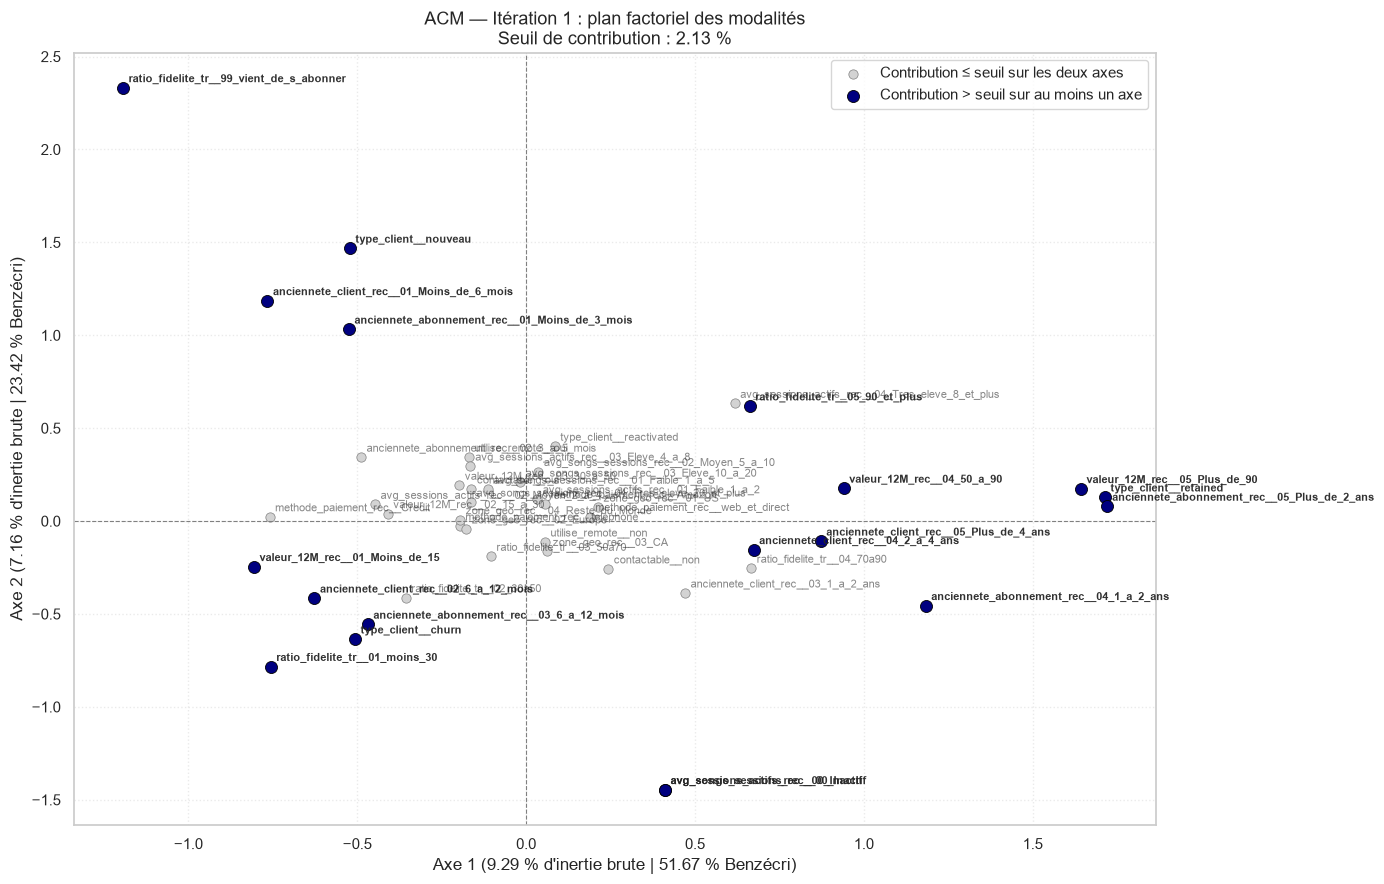

In [101]:

# ===== 9. PLAN FACTORIEL (AXES 1-2) =====

# Vérifier que les axes 1 et 2 sont disponibles
colonnes_requises = [
    "Coord Axe 1", "Coord Axe 2",
    "Contrib Axe 1 (%)", "Contrib Axe 2 (%)"
]

colonnes_manquantes = [
    c for c in colonnes_requises
    if c not in tableau_modalites.columns
]

if colonnes_manquantes:
    raise ValueError(
        f"Colonnes manquantes pour le plan factoriel : {colonnes_manquantes}"
    )

# Une modalité est mise en évidence si sa contribution dépasse
# le seuil sur au moins un des deux axes
contribue_plan = (
    tableau_modalites[
        ["Contrib Axe 1 (%)", "Contrib Axe 2 (%)"]
    ].ge(seuil_contribution).any(axis=1)
)

plt.figure(figsize=(14, 9))

# Modalités sous le seuil sur les deux axes
plt.scatter(
    tableau_modalites.loc[~contribue_plan, "Coord Axe 1"],
    tableau_modalites.loc[~contribue_plan, "Coord Axe 2"],
    color="lightgrey",
    s=45,
    edgecolor="grey",
    linewidth=0.5,
    label="Contribution ≤ seuil sur les deux axes",
    zorder=2
)

# Modalités dépassant le seuil sur au moins un axe
plt.scatter(
    tableau_modalites.loc[contribue_plan, "Coord Axe 1"],
    tableau_modalites.loc[contribue_plan, "Coord Axe 2"],
    color="navy",
    s=75,
    edgecolor="black",
    linewidth=0.6,
    label="Contribution > seuil sur au moins un axe",
    zorder=3
)

# Étiquettes des modalités
for nom, ligne in tableau_modalites.iterrows():
    plt.annotate(
        str(nom),
        (
            ligne["Coord Axe 1"],
            ligne["Coord Axe 2"]
        ),
        xytext=(4, 4),
        textcoords="offset points",
        fontsize=8,
        fontweight="bold" if contribue_plan.loc[nom] else "normal",
        alpha=0.95 if contribue_plan.loc[nom] else 0.55
    )

# Axes de référence
plt.axhline(0, color="grey", linestyle="--", linewidth=0.8)
plt.axvline(0, color="grey", linestyle="--", linewidth=0.8)

# Titres et libellés
plt.title(
    f"ACM — Itération {NUMERO_ITERATION} : plan factoriel des modalités\n"
    f"Seuil de contribution : {seuil_contribution:.2f} %",
    fontsize=13
)

plt.xlabel(
    f"Axe 1 ({brute[0]:.2f} % d'inertie brute"
    + (f" | {benzecri[0]:.2f} % Benzécri)" if len(benzecri) > 0 else ")")
)

plt.ylabel(
    f"Axe 2 ({brute[1]:.2f} % d'inertie brute"
    + (f" | {benzecri[1]:.2f} % Benzécri)" if len(benzecri) > 1 else ")")
)

plt.legend()
plt.grid(True, linestyle=":", alpha=0.4)
plt.tight_layout()
plt.show()


In [ ]:

# ===== 10. OBJETS POUR LA CAH =====
modele_final = modele
colonnes_finales = list(tableau_disjonctif.columns)
variables_finales = sorted({variable_de(m) for m in colonnes_finales})
coordonnees_individus = modele_final.row_coordinates(tableau_disjonctif).iloc[:, :N_AXES_TABLEAU]